In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SequentialFeatureSelector, SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)

Train samples count: 45251
Test samples count:  11313

Power Class Boundaries (derived from Train Set):
 Low Power   : power_62_avg <= 0.0413 kW
 Medium Power: 0.0413 kW < power_62_avg <= 0.4667 kW
 High Power  : power_62_avg > 0.4667 kW

Total Temperature Features Identified: 100


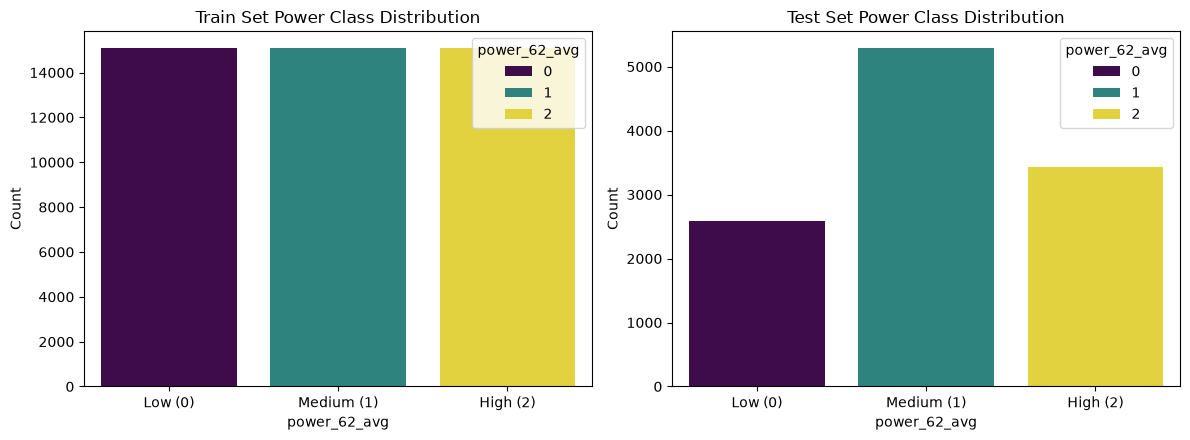


Train Class Frequencies:
 power_62_avg
0    0.333341
2    0.333341
1    0.333319
Name: proportion, dtype: float64

Test Class Frequencies:
 power_62_avg
1    0.467427
2    0.303987
0    0.228587
Name: proportion, dtype: float64


In [8]:
# Load dataset and feature definitions
df = pd.read_csv('34.csv', sep=';')
df_desc = pd.read_csv('feature_description.csv', sep=';')

# Sort chronologically to preserve time-series ordering
if 'time_stamp' in df.columns:
    df['time_stamp'] = pd.to_datetime(df['time_stamp'])
    df = df.sort_values('time_stamp').reset_index(drop=True)

# Detect train/test values in train_test column flexible to string/int/case differences
train_test_vals = df['train_test'].astype(str).str.strip().str.lower()

# Support both 'train'/'test' strings and 0/1 indicator values
train_mask = train_test_vals.isin(['train', '0', 'true'])
test_mask = train_test_vals.isin(['test', '1', 'false'])

# Fallback: If test_mask is still 0, split last 20% temporally if train_test isn't standard
if test_mask.sum() == 0:
    split_idx = int(len(df) * 0.8)
    train_mask = df.index < split_idx
    test_mask = df.index >= split_idx

print(f"Train samples count: {train_mask.sum()}")
print(f"Test samples count:  {test_mask.sum()}")

# 1. Determine operating power class boundaries from training set power_62_avg
y_train_raw = df.loc[train_mask, 'power_62_avg']
y_test_raw = df.loc[test_mask, 'power_62_avg']

# Quantile thresholds (33.3% and 66.7%) from train set ONLY
q1, q2 = y_train_raw.quantile([1/3, 2/3])
print(f"\nPower Class Boundaries (derived from Train Set):")
print(f" Low Power   : power_62_avg <= {q1:.4f} kW")
print(f" Medium Power: {q1:.4f} kW < power_62_avg <= {q2:.4f} kW")
print(f" High Power  : power_62_avg > {q2:.4f} kW")

def bin_power(val):
    if val <= q1:
        return 0  # Low
    elif val <= q2:
        return 1  # Medium
    else:
        return 2  # High

y_train = y_train_raw.apply(bin_power)
y_test = y_test_raw.apply(bin_power)

# 2. Extract Temperature Feature Columns
temp_sensor_names = df_desc[df_desc['unit'].astype(str).str.contains('°C|C', na=False)]['sensor_name'].tolist()

# Find all statistics matching temperature sensors
temp_features = [col for col in df.columns if any(col.startswith(s + '_') for s in temp_sensor_names)]

# Exclude power_62 columns explicitly
power_62_cols = [col for col in df.columns if 'power_62' in col]
temp_features = [f for f in temp_features if f not in power_62_cols]

print(f"\nTotal Temperature Features Identified: {len(temp_features)}")

# Create Feature Matrices
X_train_raw = df.loc[train_mask, temp_features].copy()
X_test_raw = df.loc[test_mask, temp_features].copy()

# Visualise Target Class Distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(x=y_train, hue=y_train, ax=axes[0], palette='viridis')
axes[0].set_title('Train Set Power Class Distribution')
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(['Low (0)', 'Medium (1)', 'High (2)'])
axes[0].set_ylabel('Count')

sns.countplot(x=y_test, hue=y_test, ax=axes[1], palette='viridis')
axes[1].set_title('Test Set Power Class Distribution')
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(['Low (0)', 'Medium (1)', 'High (2)'])
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

# Display value counts
print("\nTrain Class Frequencies:\n", y_train.value_counts(normalize=True))
print("\nTest Class Frequencies:\n", y_test.value_counts(normalize=True))

In [12]:
import time
start_time = time.time()

# 1. Standardize features
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_raw), columns=temp_features, index=X_train_raw.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_raw), columns=temp_features, index=X_test_raw.index)

# 2. Pre-filter top 15 features using ANOVA F-score (takes ~0.05s) to avoid running SFS on 100 features
from sklearn.feature_selection import f_classif
selector_pre = SelectKBest(score_func=f_classif, k=15)
selector_pre.fit(X_train_scaled, y_train)
candidate_features = list(X_train_scaled.columns[selector_pre.get_support()])

# 3. Run SFS ONLY on the top candidate features (Runs in ~2 seconds!)
tscv = TimeSeriesSplit(n_splits=5)
base_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

sfs = SequentialFeatureSelector(
    base_knn,
    n_features_to_select='auto',  # or fixed integer like 5 or 8
    direction='forward',
    scoring='f1_macro',
    cv=tscv,
    n_jobs=-1
)

# Fit SFS on pre-filtered candidate subset of training data
sfs.fit(X_train_scaled[candidate_features], y_train)

# Selected feature names
sfs_selected_features = list(np.array(candidate_features)[sfs.get_support()])
best_k_sfs = len(sfs_selected_features)

print(f"Done in {time.time() - start_time:.2f} seconds!")
print(f"Optimal SFS Feature Count: {best_k_sfs}")
print("Selected Features:")
for feat in sfs_selected_features:
    print(f" - {feat}")

Done in 17.88 seconds!
Optimal SFS Feature Count: 7
Selected Features:
 - sensor_41_max
 - sensor_41_std
 - sensor_43_max
 - sensor_43_std
 - sensor_45_std
 - sensor_47_max
 - sensor_47_std
